<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and response provenance](README.md)

# 01 · A drive filter changes the denominator

How many yards did each team gain per recorded drive, and how does requiring more plays change the comparison? We will retain short and negative-yard possessions, distinguish two kinds of average, and test one minimum-play rule on a single completed game.

**Historical ESPN game 401769076, Miami at Indiana.** Default replay uses a field projection of an actual public response captured on **2026-11-14 UTC**: all game-header information and all 22 drive rows are retained; nested plays and unrelated editorial/betting sections are omitted. No drive rows or retained values are invented. Live mode requests the same game. These descriptive summaries are not an overall team ranking or an explanation of the final score.

## Select a minimum recorded workload

`DATA_MODE` is **"replay"** or **"live"**. Replay accepts only the recorded summary request; live has no fixture fallback. `MIN_OFFENSIVE_PLAYS` is an integer from **1 to 10**, inclusive. A drive is selected when its reported `offensive_plays` is **at least** that minimum and its yardage is known.

Default **1** keeps every drive with a positive known play count and known yardage. The experiment changes it to **4**. This is an illustrative selection rule, not a definition of a valid possession. A short drive can be a rapid touchdown, a failed possession or an intentional clock-management series. Restart Kernel → Run All after editing.

In [1]:
DATA_MODE = "replay"  # "replay" or "live"; fixed historical game 401769076
MIN_OFFENSIVE_PLAYS = 1  # Inclusive minimum; experiment: 4

In [2]:
import hashlib
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.patches import Patch

from replay_source import ReplaySource, request_key

assert DATA_MODE in {"replay", "live"}
assert (
    isinstance(MIN_OFFENSIVE_PLAYS, int)
    and not isinstance(MIN_OFFENSIVE_PLAYS, bool)
    and 1 <= MIN_OFFENSIVE_PLAYS <= 10
)
manifest = json.loads(Path("fixtures/manifest.json").read_text())
env_keys = [
    "NCAAF_API_ROOT",
    "NCAAF_SITE_API_BASE_URL",
    "NCAAF_SITE_V3_API_BASE_URL",
    "NCAAF_STANDINGS_API_BASE_URL",
    "NCAAF_CORE_API_BASE_URL",
    "NCAAF_COMMON_API_BASE_URL",
    "NCAAF_MIN_REQUEST_INTERVAL",
]
previous_env = {key: os.environ.pop(key, None) for key in env_keys}
replay = ReplaySource(Path("fixtures")) if DATA_MODE == "replay" else None
if replay:
    os.environ["NCAAF_API_ROOT"] = replay.url
os.environ["NCAAF_MIN_REQUEST_INTERVAL"] = "0.25"
started = datetime.now(UTC)
colors = {84: "#a14d46", 2390: "#287d85"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def number(value):
    return "unavailable" if pd.isna(value) else f"{value:.3f}"


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Source: ESPN summary · game 401769076 · {DATA_MODE} · retrieved {source_time} · reported drive fields",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.94))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-ncaa-football/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-ncaa-football/notebooks/pyproject.toml.

## Materialize the game and its drive records

The literal uvx Git-tag location launches the pinned real worker without a local checkout. Both functions read the same game-summary endpoint, which is cached in the worker process. No schedule scan, additional game lookup, SQL LIMIT or network-side drive filter is needed.

The worker exposes completed `drives.previous` records; it does not append an in-progress drive. We require a final game before interpreting this as its recorded drive list. `start_time AT TIME ZONE 'UTC'` makes kickoff timezone explicit; the season label can refer to the prior calendar year for a January postseason game.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ncaa_football' (
 TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-ncaa-football@v0.2.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with httpx==0.28.1 --with httpx2==2.16.0 --with pyarrow==25.0.1 vgi-ncaa-football'
);
CREATE TABLE game AS SELECT * FROM ncaa_football.main.game_summary(401769076);
CREATE TABLE drives AS SELECT * FROM ncaa_football.main.drives(401769076);
CREATE TABLE teams AS
SELECT home_team_id AS team_id,home_team_abbreviation AS team,home_score AS final_points FROM game
UNION ALL SELECT away_team_id,away_team_abbreviation,away_score FROM game;

,Count


In [4]:
%%sql game_info <<
SELECT name,season,start_time AT TIME ZONE 'UTC' AS kickoff_utc,completed,
 home_team_abbreviation,home_score,away_team_abbreviation,away_score
FROM game;

In [5]:
%%sql availability <<
SELECT team_abbreviation,count(*) AS recorded_drives,
 count(*) FILTER(WHERE offensive_plays IS NULL) AS missing_play_count,
 count(*) FILTER(WHERE offensive_plays=0) AS zero_play_count,
 count(*) FILTER(WHERE yards IS NULL) AS missing_yards,
 count(*) FILTER(WHERE yards<0) AS negative_yard_drives,
 count(*) FILTER(WHERE result IN ('END OF HALF','END OF GAME')) AS clock_boundary_results
FROM drives GROUP BY team_abbreviation ORDER BY team_abbreviation;

In [6]:
retrieved = datetime.now(UTC)
source_time = (manifest["capture_finished_utc"] if replay else retrieved.isoformat())[:19] + " UTC"
assert len(game_info) == 1 and bool(game_info.completed.iloc[0])
assert con.execute("SELECT count(*)=count(DISTINCT drive_id) AND count(*)>0 FROM drives").fetchone()[0]
assert (
    con.execute(
        "SELECT count(*) FROM drives WHERE drive_id IS NULL OR game_id<>401769076 OR offensive_plays<0"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM drives d LEFT JOIN teams t USING(team_id) WHERE t.team_id IS NULL"
    ).fetchone()[0]
    == 0
)
fingerprint = hashlib.sha256(
    json.dumps(
        con.execute(
            "SELECT drive_id,drive_number,team_id,offensive_plays,yards,result FROM drives ORDER BY drive_number"
        ).fetchall(),
        separators=(",", ":"),
    ).encode()
).hexdigest()
if replay:
    assert sorted(map(request_key, replay.requests)) == sorted(
        request_key(e["request_path"]) for e in manifest["entries"]
    )
    raw = json.loads(Path("fixtures/summary.json").read_text())["drives"]["previous"]
    expected = sorted(
        (int(d["id"]), int(d["team"]["id"]), d.get("offensivePlays"), d.get("yards")) for d in raw
    )
    assert (
        expected
        == con.execute(
            "SELECT drive_id,team_id,offensive_plays,yards FROM drives ORDER BY drive_id"
        ).fetchall()
    )
    request_note = f"Replay served **{len(replay.requests)} exact request**; all **{len(raw)} retained drive rows** agree with the returned IDs, teams, play counts and yards."
else:
    request_note = f"Live retrieval ran from **{started.isoformat()}** to **{retrieved.isoformat()}**. HTTP attempts are not instrumented; retries may occur."
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/request-audit.json").write_text(
    json.dumps(
        {
            "mode": DATA_MODE,
            "requests": replay.requests if replay else None,
            "fingerprint": fingerprint,
            "started_utc": started.isoformat(),
            "finished_utc": retrieved.isoformat(),
        },
        indent=2,
    )
)
display(game_info)
display(availability)
prose(
    f"{request_note} **{int(availability.negative_yard_drives.sum())} drives** have negative yardage, and **{int(availability.clock_boundary_results.sum())}** end at a half/game boundary. Neither is automatically discarded. Source time: **{source_time}**; kickoff above is a separate historical timestamp. Drive fingerprint: `{fingerprint}`."
)

,name,season,kickoff_utc,completed,home_team_abbreviation,home_score,away_team_abbreviation,away_score
0,Miami Hurricanes at Indiana Hoosiers,2025,2026-01-20 00:30:00,True,IU,27,MIA,21


,team_abbreviation,recorded_drives,missing_play_count,zero_play_count,missing_yards,negative_yard_drives,clock_boundary_results
0,IU,11,0,0,0,3,2
1,MIA,11,0,0,0,1,0


Replay served **1 exact request**; all **22 retained drive rows** agree with the returned IDs, teams, play counts and yards. **4 drives** have negative yardage, and **2** end at a half/game boundary. Neither is automatically discarded. Source time: **2026-11-14T08:33:45 UTC**; kickoff above is a separate historical timestamp. Drive fingerprint: `fe816ad8890ac3c9127bd33573713e2158c7260c7f2e7a50276ecefeeb29411d`.

## Show what the rule selects before averaging

Preserve the original drive order and mark selected versus omitted records. Negative yardage stays signed. The baseline for arithmetic consists of known yards and a positive known play count; missing or zero-count records remain in the availability table, with no invented rate.

These are ESPN's reported drive yards and reported offensive-play counts. They are not reconstructed from every play and need not equal an official box-score yards-per-play statistic. Drive `result` and `is_score` are descriptive labels; they do not alone establish which team received points, so we do not infer a scoreboard from touchdown labels.

In [7]:
%%sql
CREATE TABLE measured AS
SELECT *,1.0*yards/nullif(offensive_plays,0) AS drive_yards_per_play,
 offensive_plays>={{MIN_OFFENSIVE_PLAYS}} AS selected
FROM drives WHERE yards IS NOT NULL AND offensive_plays>0;
CREATE TABLE selected AS SELECT * FROM measured WHERE selected;

,Count


In [8]:
%%sql drive_table <<
SELECT drive_number,team_abbreviation,offensive_plays,yards,result,selected
FROM measured ORDER BY drive_number;

,drive_number,team_abbreviation,offensive_plays,yards,result,selected
0,1,MIA,5,20,PUNT,True
1,2,IU,4,13,PUNT,True
2,3,MIA,3,5,PUNT,True
3,4,IU,12,55,FG,True
4,5,MIA,3,-7,PUNT,True
5,6,IU,3,-1,PUNT,True
6,7,MIA,3,8,PUNT,True
7,8,IU,14,85,TD,True
8,9,MIA,9,43,MISSED FG,True
9,10,IU,3,18,END OF HALF,True


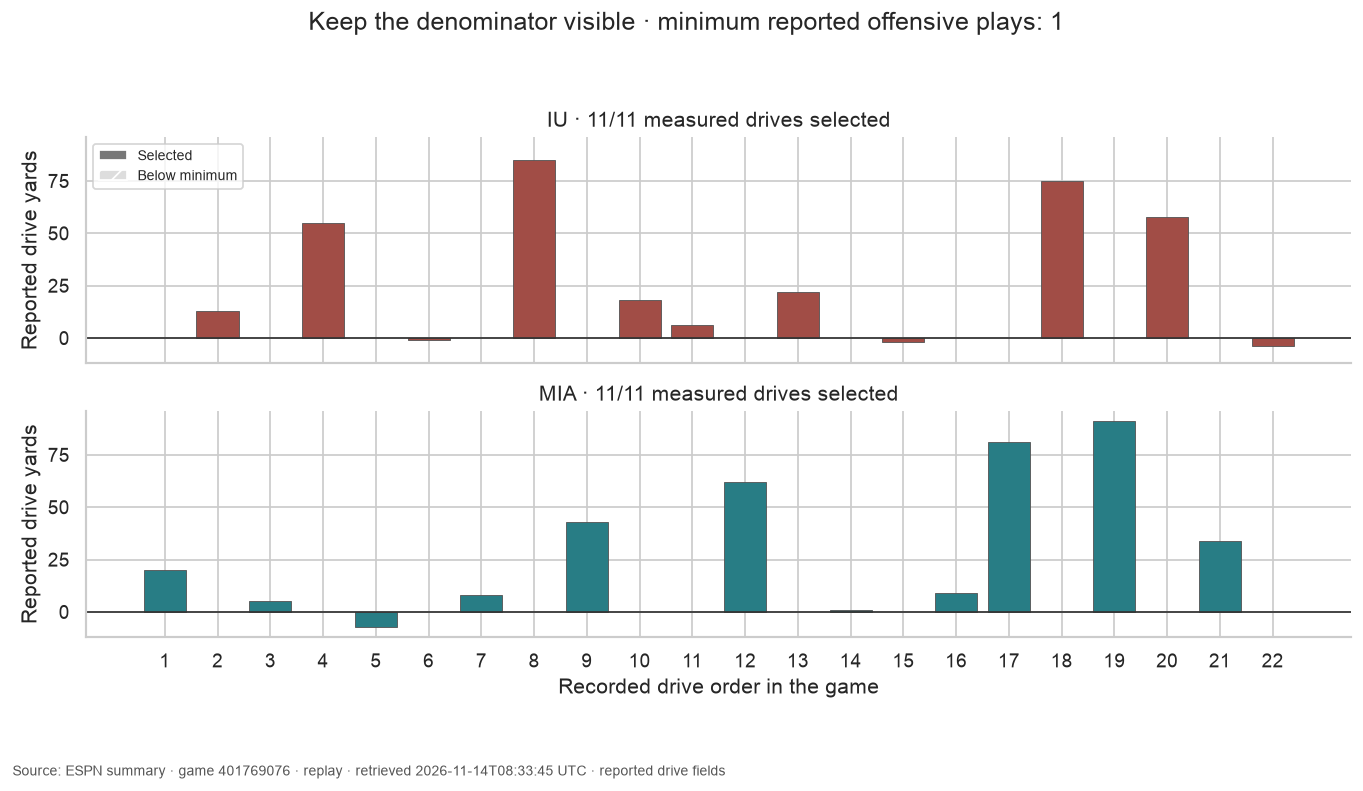

In [9]:
display(drive_table)
assert (
    con.execute(
        "SELECT count(*) FROM measured WHERE selected IS DISTINCT FROM (offensive_plays>=?)",
        [MIN_OFFENSIVE_PLAYS],
    ).fetchone()[0]
    == 0
)
assert con.execute("SELECT count(*) FROM measured WHERE drive_yards_per_play IS NULL").fetchone()[0] == 0
measured = con.execute("SELECT * FROM measured ORDER BY drive_number").df()
team_rows = con.execute("SELECT * FROM teams ORDER BY team").df()
fig, axes = plt.subplots(len(team_rows), 1, figsize=(11, 6.3), sharex=True, sharey=True, squeeze=False)
for ax, team in zip(axes.flat, team_rows.itertuples(), strict=True):
    rows = measured[measured.team_id == team.team_id]
    for r in rows.itertuples():
        ax.bar(
            r.drive_number,
            r.yards,
            color=colors.get(team.team_id, "#666666"),
            alpha=1 if r.selected else 0.25,
            hatch=None if r.selected else "//",
            edgecolor="#555555",
            linewidth=0.5,
        )
    ax.axhline(0, color="#333333", linewidth=1)
    ax.set(
        title=f"{team.team} · {int(rows.selected.sum())}/{len(rows)} measured drives selected",
        ylabel="Reported drive yards",
    )
axes[-1, 0].set(xlabel="Recorded drive order in the game", xticks=measured.drive_number)
axes[0, 0].legend(
    handles=[
        Patch(facecolor="#777777", label="Selected"),
        Patch(facecolor="#dddddd", hatch="//", label="Below minimum"),
    ],
    loc="upper left",
    fontsize=8,
)
fig.suptitle(f"Keep the denominator visible · minimum reported offensive plays: {MIN_OFFENSIVE_PLAYS}")
finish(fig)

## Use a ratio of sums for a play-weighted summary

Mean yards per drive is `sum(yards) / count(drives)`. Yards per reported play is `sum(yards) / sum(offensive_plays)`. In contrast, `avg(yards / offensive_plays)` gives every drive equal weight, including a short burst and a long possession. The table shows both play-rate summaries so the denominator is inspectable.

Aggregate by stable team ID, then join to the two teams from the game header. A team with no selected drives would retain a zero selected count and unavailable selected rates. The final score is context; these metrics are not substitutes for points.

In [10]:
%%sql
CREATE TABLE comparisons AS
WITH full_pool AS (
 SELECT team_id,count(*) AS all_drives,sum(yards) AS all_yards,
 sum(offensive_plays) AS all_plays,avg(yards) AS all_yards_per_drive,
 1.0*sum(yards)/nullif(sum(offensive_plays),0) AS all_yards_per_play
 FROM measured GROUP BY team_id
), chosen AS (
 SELECT team_id,count(*) AS selected_drives,sum(yards) AS selected_yards,
 sum(offensive_plays) AS selected_plays,avg(yards) AS selected_yards_per_drive,
 1.0*sum(yards)/nullif(sum(offensive_plays),0) AS selected_yards_per_play,
 avg(drive_yards_per_play) AS equal_drive_mean_rate
 FROM selected GROUP BY team_id
)
SELECT t.*,f.* EXCLUDE(team_id),coalesce(s.selected_drives,0) AS selected_drives,
 s.selected_yards,s.selected_plays,s.selected_yards_per_drive,
 s.selected_yards_per_play,s.equal_drive_mean_rate
FROM teams t LEFT JOIN full_pool f USING(team_id) LEFT JOIN chosen s USING(team_id);

,Count


In [11]:
%%sql summary <<
SELECT team,final_points,all_drives,selected_drives,selected_yards,selected_plays,
 all_yards_per_drive,selected_yards_per_drive,
 all_yards_per_play,selected_yards_per_play,equal_drive_mean_rate
FROM comparisons ORDER BY team;

,team,final_points,all_drives,selected_drives,selected_yards,selected_plays,all_yards_per_drive,selected_yards_per_drive,all_yards_per_play,selected_yards_per_play,equal_drive_mean_rate
0,IU,27,11,11,325.0,74.0,29.545455,29.545455,4.391892,4.391892,3.175226
1,MIA,21,11,11,347.0,55.0,31.545455,31.545455,6.309091,6.309091,6.421465


**IU: 11/11 measured drives selected.** Yards per drive: **29.545 → 29.545**. Yards per reported play: **4.392 → 4.392**; equal-drive mean of individual play rates: **3.175**. Final points remain **27**. The two averaging rules weight the selected drives differently.

**MIA: 11/11 measured drives selected.** Yards per drive: **31.545 → 31.545**. Yards per reported play: **6.309 → 6.309**; equal-drive mean of individual play rates: **6.421**. Final points remain **21**. The two averaging rules weight the selected drives differently.

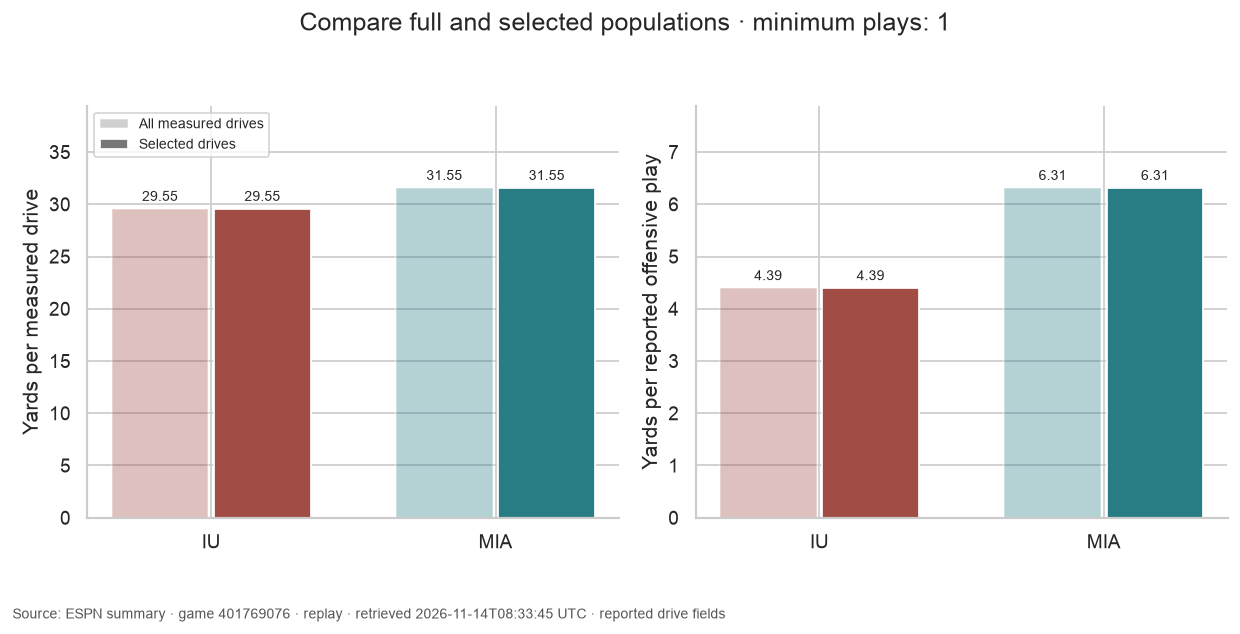

In [12]:
display(summary)
assert con.execute("SELECT count(*) FROM comparisons WHERE selected_drives>all_drives").fetchone()[0] == 0
assert con.execute(
    "SELECT bool_and(abs(rate-weighted)<1e-10) FROM (SELECT team_id,sum(yards)*1.0/sum(offensive_plays) AS rate,sum(drive_yards_per_play*offensive_plays)/sum(offensive_plays) AS weighted FROM selected GROUP BY team_id)"
).fetchone()[0]
assert (
    con.execute(
        "SELECT count(*) FROM comparisons c LEFT JOIN (SELECT team_id,sum(yards) AS omitted_yards,sum(offensive_plays) AS omitted_plays FROM measured WHERE NOT selected GROUP BY team_id) o USING(team_id) WHERE coalesce(c.selected_yards,0)+coalesce(o.omitted_yards,0)<>c.all_yards OR coalesce(c.selected_plays,0)+coalesce(o.omitted_plays,0)<>c.all_plays"
    ).fetchone()[0]
    == 0
)
for r in summary.itertuples():
    prose(
        f"**{r.team}: {r.selected_drives}/{r.all_drives} measured drives selected.** Yards per drive: **{number(r.all_yards_per_drive)} → {number(r.selected_yards_per_drive)}**. Yards per reported play: **{number(r.all_yards_per_play)} → {number(r.selected_yards_per_play)}**; equal-drive mean of individual play rates: **{number(r.equal_drive_mean_rate)}**. Final points remain **{r.final_points}**. The two averaging rules weight the selected drives differently."
    )
comparison = con.execute("SELECT * FROM comparisons ORDER BY team").df()
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, metric, label in zip(
    axes,
    ["yards_per_drive", "yards_per_play"],
    ["Yards per measured drive", "Yards per reported offensive play"],
    strict=True,
):
    for i, r in enumerate(comparison.itertuples()):
        for offset, prefix, alpha in [(-0.18, "all_", 0.35), (0.18, "selected_", 1)]:
            value = getattr(r, prefix + metric)
            if pd.notna(value):
                bars = ax.bar(
                    i + offset, value, width=0.34, color=colors.get(r.team_id, "#666666"), alpha=alpha
                )
                ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
            else:
                ax.text(i + offset, 0, "unavailable", rotation=90, va="bottom", ha="center", fontsize=8)
    ax.set(xticks=range(len(comparison)), xticklabels=comparison.team, ylabel=label)
    ax.axhline(0, color="#333333", linewidth=0.8)
    ax.margins(y=0.25)
axes[0].legend(
    handles=[
        Patch(facecolor="#777777", alpha=0.35, label="All measured drives"),
        Patch(facecolor="#777777", label="Selected drives"),
    ],
    loc="upper left",
    fontsize=8,
)
fig.suptitle(f"Compare full and selected populations · minimum plays: {MIN_OFFENSIVE_PLAYS}")
finish(fig)

## Experiment: require at least four reported offensive plays

Keep `DATA_MODE="replay"` and change only `MIN_OFFENSIVE_PLAYS` from **1 to 4**. Predict fewer selected drives. Do not assume the rate must improve: the omitted set can contain negative-yard possessions and short long-yardage possessions alike. Compare each team's selected count, yards per drive, ratio-of-sums play rate and equal-drive mean rate.

The raw drive fingerprint, final score and full measured-pool summaries must stay unchanged. The hatched bars identify the omitted records. Restore **1** afterwards. This is selection sensitivity within one game, not evidence for a general minimum-drive rule or a causal explanation of the outcome.

In [13]:
con.close()
if replay:
    replay.close()
for key, value in previous_env.items():
    if value is None:
        os.environ.pop(key, None)
    else:
        os.environ[key] = value

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)